# Planta Física: a capacity-aware mutation operator

MA2015.202 · March 2025 · Operator-modification deliverable.

**Team:** Ángel Nicolás Landa Tapia (A01668133), Luis Fernando Salas López (A01770922), Claudio Ahuatzi Quintana (A01661936).

In this notebook we change one genetic operator, **mutation**, and compare the modified GA with the supplied baseline under identical conditions (seed 42). The baseline is preserved in two ways:

1. The original notebook, `planta_fisica_minimum_solution.ipynb`, is not modified.
2. Here we copy the baseline evaluator and operators verbatim, and in Section 5 we check that our copy reproduces the original baseline result exactly, gene by gene and generation by generation.

Selection (binary tournament), crossover (one-point), replacement (one elite), initialization, data, capacity and every parameter stay the same. Only the mutation operator changes.

## 1. Model and evaluator (unchanged)

The data, gene domains, teaching capacity and fitness are those of the baseline notebook: $T=\sum_iD_ik_i/10$, $P=\sum_iD_i-T$, $E=\max(0,T-1410)$; $F=P/\sum_iD_i$ if feasible and $F=1+E/1410$ otherwise (lower is better).

In [1]:
import itertools
import math

import matplotlib.pyplot as plt
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity


def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

## 2. Baseline operators (verbatim copies)

These four functions are copied unchanged from the baseline notebook. `mutate` is the baseline mutation operator that we will compare against.

In [2]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)


def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()


def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))


def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

## 3. The limitation we address

The baseline mutation does not use the capacity constraint. When a gene is selected, it moves up or down with equal probability (only one direction at a domain edge), whatever the current $T$ is. In this problem, good plans sit just below $C=1410$ m³. One level of each building is worth a fixed amount of treated water, so the size of a single step depends on the building:

| Building | One level $=D_i/10$ (m³) |
|---|---:|
| Aulas 1 | 84.700 |
| Biblioteca | 46.200 |
| Cedetec | 28.421 |
| Aulas 2 | 68.300 |

Once a plan's slack $C-T$ is below 28.421 m³, **every** upward step makes it infeasible. Its fitness then jumps above 1 and it cannot win a tournament against any feasible plan. For good parents, about half of the mutated genes are therefore wasted offspring. A downward step stays feasible but adds 28–85 m³ of potable water. An improvement near the boundary needs a *coordinated* move: lower one building and raise another with a smaller step. Blind mutation produces such pairs rarely, and when the order is wrong it produces an infeasible plan.

The cell below shows this with the baseline's own best plan at seed 42, (7,4,3,8): it has only 0.637 m³ of slack, and each possible upward step breaks capacity.

In [3]:
near_boundary = np.array([7, 4, 3, 8])
m = evaluate(near_boundary)
print(f"Plan {near_boundary}: T = {m['treated']:.3f} m3, slack = {CAPACITY - m['treated']:.3f} m3")
for i, name in enumerate(BUILDINGS):
    for step in (-1, +1):
        trial = near_boundary.copy()
        trial[i] += step
        if not 0 <= trial[i] <= LIMITS[i]:
            continue
        t = evaluate(trial)
        print(f"  {name:<10} {step:+d}: T = {t['treated']:8.3f}  E = {t['excess']:6.3f}  "
              f"feasible = {t['feasible']!s:<5}  F = {t['fitness']:.4f}")

Plan [7 4 3 8]: T = 1409.363 m3, slack = 0.637 m3
  AULAS 1    -1: T = 1324.663  E =  0.000  feasible = True   F = 0.4180
  AULAS 1    +1: T = 1494.063  E = 84.063  feasible = False  F = 1.0596
  BIBLIOTECA -1: T = 1363.163  E =  0.000  feasible = True   F = 0.4011
  BIBLIOTECA +1: T = 1455.563  E = 45.563  feasible = False  F = 1.0323
  CEDETEC    -1: T = 1380.942  E =  0.000  feasible = True   F = 0.3933
  CEDETEC    +1: T = 1437.784  E = 27.784  feasible = False  F = 1.0197
  AULAS 2    -1: T = 1341.063  E =  0.000  feasible = True   F = 0.4108


## 4. Hypothesis and the modified operator

**Hypothesis.** If mutation uses the capacity information the evaluator already provides, so that it never chooses a step that pushes a plan over capacity when a feasible step exists, then (a) far fewer offspring will be infeasible, and (b) the GA will spend its limited budget (20 × 20 evaluations) on feasible plans near the boundary. We therefore expect the final plan to use less potable water, or at least no more, than the baseline under the same seed.

**Change (capacity-aware mutation).** We keep the same per-gene probability $p$, the same ±1 step and the same gene order. When a gene is selected:

1. We compute the child's current $T$, including steps already applied to earlier genes in the same child.
2. A downward step is always allowed. An upward step is allowed only if it keeps $T\le C$.
3. The new value is drawn uniformly from the allowed steps. If no step is allowed (a gene at 0 whose only step is upward and does not fit), the gene stays unchanged. This is the only case in which a selected gene does not move. It is rare, and it is required for the guarantee below.

Consequences: a feasible child cannot become infeasible through mutation; an infeasible child (produced by crossover) can only be pushed back toward capacity; and because $T$ is updated gene by gene, a downward step on one building can make room for an upward step on a later one in the same child. This creates the coordinated moves described above. The operator is still stochastic and does not search for the best step, because we do not want to turn mutation into a greedy local search.

In [4]:
def mutate_capacity_aware(child: np.ndarray, probability: float,
                          rng: np.random.Generator) -> np.ndarray:
    """Move each selected gene one step, never choosing an upward step that breaks capacity."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            treated = float(np.sum(DEMAND * result / 10))
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            allowed = [v for v in neighbors
                       if v < result[i] or treated + DEMAND[i] / 10 <= CAPACITY + 1e-8]
            if allowed:
                result[i] = rng.choice(allowed)
    return result

We check the operator's guarantees on many random children before using it in the GA: domains are respected, a feasible child stays feasible, and an infeasible child's treated water never increases.

In [5]:
rng_check = np.random.default_rng(0)
for _ in range(5000):
    child = random_individual(rng_check)
    before = evaluate(child)
    after_genes = mutate_capacity_aware(child, 0.5, rng_check)
    after = evaluate(after_genes)  # also validates domains
    if before["feasible"]:
        assert after["feasible"]
    else:
        assert after["treated"] <= before["treated"] + 1e-9
print("Capacity-aware mutation: domains, feasibility preservation and repair direction checked.")

rng_demo = np.random.default_rng(7)
print("From the near-boundary plan (7,4,3,8) with p = 1:")
for _ in range(4):
    trial = mutate_capacity_aware(near_boundary, 1.0, rng_demo)
    t = evaluate(trial)
    print(f"   {trial}  T = {t['treated']:8.3f}  feasible = {t['feasible']}")

Capacity-aware mutation: domains, feasibility preservation and repair direction checked.
From the near-boundary plan (7,4,3,8) with p = 1:
   [6 5 4 7]  T = 1330.984  feasible = True
   [6 3 4 7]  T = 1238.584  feasible = True
   [6 5 2 7]  T = 1274.142  feasible = True
   [6 5 4 7]  T = 1330.984  feasible = True


## 5. One GA loop with a pluggable mutation operator

`run_ga` is the baseline loop with one difference: the mutation operator is passed as an argument (default: the baseline `mutate`). It also counts how many generated children are infeasible after mutation. That counter is a diagnostic only: it reads `evaluate` and draws no random numbers, so it does not change the run.

We first confirm that `run_ga(mutation_operator=mutate)` reproduces the published baseline result (genes (7,4,3,8), $F=0.380829\ldots$, first improvement at generation 17).

In [6]:
def next_generation(population: list, probability: float, rng: np.random.Generator,
                    mutation_operator=mutate, stats: dict | None = None) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        child = mutation_operator(child, probability, rng)
        if stats is not None:
            stats["children"] += 1
            stats["infeasible"] += not evaluate(child)["feasible"]
        replacement.append(child)
    return replacement


def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42,
           mutation_operator=mutate) -> dict:
    """Run the canonical GA with the chosen mutation operator."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    stats = dict(children=0, infeasible=0)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng,
                                     mutation_operator, stats)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history),
                infeasible_share=stats["infeasible"] / stats["children"],
                unique_final=len({tuple(x) for x in population}))


CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG, mutation_operator=mutate)

# Published baseline result from planta_fisica_minimum_solution.ipynb (Section 9).
np.testing.assert_array_equal(baseline["genes"], [7, 4, 3, 8])
assert np.isclose(baseline["metrics"]["fitness"], 0.38082909749100474, atol=1e-15)
assert np.isclose(baseline["metrics"]["treated"], 1409.363)
assert int(np.argmax(baseline["history"] < baseline["history"][0])) == 17
print("Baseline preserved: our run_ga reproduces the original baseline exactly.")

Baseline preserved: our run_ga reproduces the original baseline exactly.


## 6. Baseline vs. capacity-aware mutation, seed 42

Both runs use 20 individuals, 20 generations, $p=0.25$ and seed 42, so they start from the **same initial population**. The only difference is the mutation operator. We also compute the true optimum of the model by checking all 5,103 plans, so that we can report each plan's distance to it.

In [7]:
variant = run_ga(**CONFIG, mutation_operator=mutate_capacity_aware)
runs = [("Baseline (blind mutation)", baseline), ("Variant (capacity-aware)", variant)]

all_plans = [np.array(k) for k in itertools.product(*(range(limit + 1) for limit in LIMITS))]
optimum = min(all_plans, key=lambda x: evaluate(x)["fitness"])
opt = evaluate(optimum)
print(f"Exhaustive optimum: {optimum}, T = {opt['treated']:.3f} m3, P = {opt['potable']:.3f} m3\n")

for label, result in runs:
    g, mt = result["genes"], result["metrics"]
    print(label)
    print(f"  chromosome k = {tuple(int(v) for v in g)}, fractions x = {tuple(float(v) for v in g / 10)}")
    print(f"  {'Building':<11}{'D (m3)':>9}{'T_i (m3)':>11}{'P_i (m3)':>11}")
    for name, d, k in zip(BUILDINGS, DEMAND, g):
        print(f"  {name:<11}{d:>9.2f}{d * k / 10:>11.3f}{d - d * k / 10:>11.3f}")
    print(f"  {'Total':<11}{DEMAND.sum():>9.2f}{mt['treated']:>11.3f}{mt['potable']:>11.3f}")
    print(f"  E = {mt['excess']:.3f} m3, slack = {CAPACITY - mt['treated']:.3f} m3, "
          f"feasible = {mt['feasible']}, F = {mt['fitness']:.6f}")
    print(f"  gap to optimum = {mt['potable'] - opt['potable']:.3f} m3 potable, "
          f"first improvement at generation {int(np.argmax(result['history'] < result['history'][0]))}, "
          f"infeasible children = {result['infeasible_share']:.1%}, "
          f"distinct plans in final population = {result['unique_final']}\n")

Exhaustive optimum: [8 6 4 5], T = 1409.984 m3, P = 866.226 m3

Baseline (blind mutation)
  chromosome k = (7, 4, 3, 8), fractions x = (0.7, 0.4, 0.3, 0.8)
  Building      D (m3)   T_i (m3)   P_i (m3)
  AULAS 1       847.00    592.900    254.100
  BIBLIOTECA    462.00    184.800    277.200
  CEDETEC       284.21     85.263    198.947
  AULAS 2       683.00    546.400    136.600
  Total        2276.21   1409.363    866.847
  E = 0.000 m3, slack = 0.637 m3, feasible = True, F = 0.380829
  gap to optimum = 0.621 m3 potable, first improvement at generation 17, infeasible children = 21.8%, distinct plans in final population = 19

Variant (capacity-aware)
  chromosome k = (5, 7, 4, 8), fractions x = (0.5, 0.7, 0.4, 0.8)
  Building      D (m3)   T_i (m3)   P_i (m3)
  AULAS 1       847.00    423.500    423.500
  BIBLIOTECA    462.00    323.400    138.600
  CEDETEC       284.21    113.684    170.526
  AULAS 2       683.00    546.400    136.600
  Total        2276.21   1406.984    869.226
  E = 

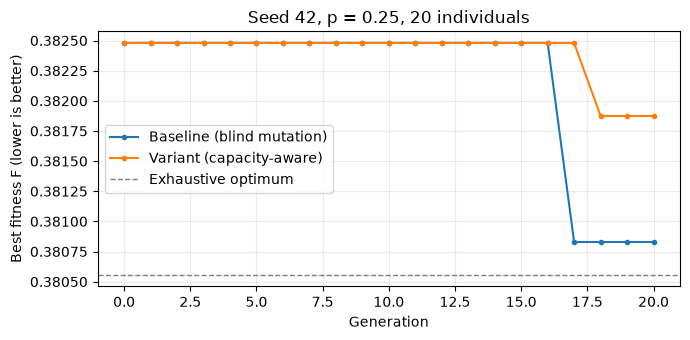

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in runs:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.axhline(opt["fitness"], color="grey", linestyle="--", linewidth=1, label="Exhaustive optimum")
ax.set(xlabel="Generation", ylabel="Best fitness F (lower is better)",
       title="Seed 42, p = 0.25, 20 individuals")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

**Interpretation (seed 42).** Both runs start from the same population (best plan (6,6,5,7), $F=0.38248$) and stay on that plateau for 16 generations.

| | Baseline (blind mutation) | Variant (capacity-aware) |
|---|---|---|
| Final chromosome $k$ | (7,4,3,8) | (5,7,4,8) |
| Reuse fractions $x$ | (0.7, 0.4, 0.3, 0.8) | (0.5, 0.7, 0.4, 0.8) |
| Treated water $T_i$ (m³): A1 / Bib / Ced / A2 | 592.900 / 184.800 / 85.263 / 546.400 | 423.500 / 323.400 / 113.684 / 546.400 |
| Potable water $P_i$ (m³): A1 / Bib / Ced / A2 | 254.100 / 277.200 / 198.947 / 136.600 | 423.500 / 138.600 / 170.526 / 136.600 |
| Total $T$ (m³) | 1409.363 | 1406.984 |
| Total $P$ (m³) | **866.847** | 869.226 |
| Excess $E$ (m³) / slack (m³) | 0 / 0.637 | 0 / 3.016 |
| Feasible | Yes | Yes |
| Fitness $F$ | **0.380829** | 0.381874 |
| Gap to optimum (8,6,4,5) (m³ potable) | 0.621 | 3.000 |
| First improvement at generation | 17 | 18 |
| Infeasible children (all 380 generated) | 21.8% | **4.2%** |

*What the evidence supports.*
- **Mechanism, part (a) of the hypothesis: supported.** The share of infeasible children fell from 21.8% to 4.2%. The remaining 4.2% are crossover children that were already over capacity and that mutation either did not touch (each gene is selected with probability 0.25) or did not lower enough. Mutation itself no longer creates infeasible plans (checked in Section 4).
- **Outcome, part (b) of the hypothesis: not supported at seed 42.** The variant's final plan is feasible but uses **2.379 m³ more potable water** than the baseline ($\Delta F=+0.00104$). With this seed, the baseline is better.

*Why fewer wasted children did not give a better plan here.* Each run improved exactly once, late (generation 17 vs. 18), so the final plan depends on a single lucky event. After the first mutation the two runs consume random numbers differently and follow different paths, so this one improvement is not a controlled consequence of the operator. The variant also has a structural limitation that this run exposes: genes are visited in a fixed order, so a step down on a building can only make room for a step up on a building that comes *later* in the chromosome. Aulas 1, the first gene and the largest step (84.7 m³), can never be raised by the variant once the plan is near capacity. Getting there needs crossover. The baseline's plan (7,4,3,8) has Aulas 1 at 70%, and the variant's plan (5,7,4,8) has it at 50%, with the treated water shifted to Biblioteca and Cedetec. Both plans keep Aulas 2 at its 80% limit.

*Physical reading.* Both plans are feasible, use more than 99.7% of the 1,410 m³ teaching capacity and cut potable water from 2,276.21 m³ to about 867–869 m³ (about 62% less). The 2.379 m³ difference is 0.1% of total demand. Different building splits reach almost the same potable use, so the choice between these two plans would in practice depend on factors the model leaves out, such as piping, water quality and cost. (The variant's plan happens to equal the $p=0.50$ result in the baseline notebook; it is a common near-boundary plan.)

## 7. Scope: is seed 42 representative?

The required comparison is the single seed-42 run above. One run cannot separate the effect of the operator from the luck of the random stream: once the operators differ, the two runs consume random numbers differently and follow different paths after the first mutation. To see how far the seed-42 result generalizes, we repeat the same paired comparison (same seed for both operators, same configuration) on seeds 0–99. This is supplementary evidence. It does not replace the seed-42 comparison.

In [9]:
SEEDS = range(100)
rows = []
for s in SEEDS:
    cfg = {**CONFIG, "seed": s}
    b = run_ga(**cfg, mutation_operator=mutate)
    v = run_ga(**cfg, mutation_operator=mutate_capacity_aware)
    rows.append((s, b["metrics"]["potable"] - opt["potable"], v["metrics"]["potable"] - opt["potable"],
                 b["metrics"]["feasible"], v["metrics"]["feasible"],
                 b["infeasible_share"], v["infeasible_share"]))
seeds, gap_b, gap_v, feas_b, feas_v, inf_b, inf_v = map(np.array, zip(*rows))

diff = gap_v - gap_b  # negative: variant uses less potable water
wins, ties, losses = int(np.sum(diff < -1e-6)), int(np.sum(np.abs(diff) <= 1e-6)), int(np.sum(diff > 1e-6))
n = wins + losses
sign_p = min(1.0, 2 * sum(math.comb(n, j) for j in range(min(wins, losses) + 1)) / 2 ** n)

print(f"{'':<28}{'Baseline':>10}{'Variant':>10}")
print(f"{'Feasible final plans':<28}{feas_b.sum():>10d}{feas_v.sum():>10d}")
print(f"{'Optimum found (gap = 0)':<28}{np.sum(gap_b < 1e-6):>10d}{np.sum(gap_v < 1e-6):>10d}")
print(f"{'Mean gap (m3 potable)':<28}{gap_b.mean():>10.3f}{gap_v.mean():>10.3f}")
print(f"{'Median gap (m3 potable)':<28}{np.median(gap_b):>10.3f}{np.median(gap_v):>10.3f}")
print(f"{'Worst gap (m3 potable)':<28}{gap_b.max():>10.3f}{gap_v.max():>10.3f}")
print(f"{'Mean infeasible children':<28}{inf_b.mean():>10.1%}{inf_v.mean():>10.1%}")
print(f"\nPaired by seed: variant better in {wins}, equal in {ties}, worse in {losses} of {len(seeds)} seeds")
print(f"Two-sided sign test on the {n} untied seeds: p = {sign_p:.3f}")
print(f"Seed 42 rank among seeds by (variant - baseline) gap: "
      f"{int(np.sum(diff > diff[seeds == 42][0]))} seeds were worse for the variant than seed 42")

                              Baseline   Variant
Feasible final plans               100       100
Optimum found (gap = 0)             15        18
Mean gap (m3 potable)            2.285     1.603
Median gap (m3 potable)          2.000     0.621
Worst gap (m3 potable)          13.079     8.321
Mean infeasible children         16.3%      6.6%

Paired by seed: variant better in 49, equal in 17, worse in 34 of 100 seeds
Two-sided sign test on the 83 untied seeds: p = 0.124
Seed 42 rank among seeds by (variant - baseline) gap: 17 seeds were worse for the variant than seed 42


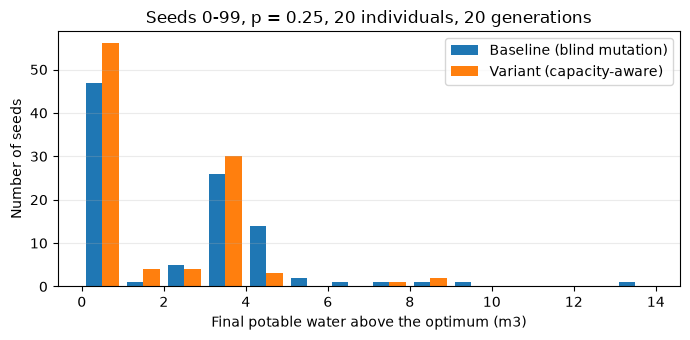

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.arange(0, max(gap_b.max(), gap_v.max()) + 1.5, 1.0)
ax.hist([gap_b, gap_v], bins=bins, label=["Baseline (blind mutation)", "Variant (capacity-aware)"])
ax.set(xlabel="Final potable water above the optimum (m3)", ylabel="Number of seeds",
       title="Seeds 0-99, p = 0.25, 20 individuals, 20 generations")
ax.grid(alpha=0.25, axis="y")
ax.legend()
fig.tight_layout()
plt.show()

**Interpretation (scope).** Over 100 paired seeds:

- Both operators always ended with a feasible plan, so the change does not affect feasibility of the final answer. Elitism plus the penalty already ensures that.
- The variant reduced infeasible children on average from 16.3% to 6.6%, consistent with seed 42. The mechanism is reproducible.
- The variant had a lower mean gap (1.603 vs. 2.285 m³), a lower median gap (0.621 vs. 2.000 m³), a smaller worst case (8.321 vs. 13.079 m³) and found the exact optimum more often (18 vs. 15 seeds).
- Paired by seed, the variant was better in 49 seeds, equal in 17 and worse in 34. A two-sided sign test gives $p=0.124$, so the advantage is a **trend, not a statistically established improvement**, at this budget and sample size.
- Seed 42 falls in the variant's unfavorable tail: only 17 of the 100 seeds had a larger loss for the variant. The seed-42 comparison is honest evidence, but on its own it would have suggested the opposite of the typical behavior.

**Scope of the conclusion.** These results hold for this teaching model only: four buildings, March 2025 demand, the 1,410 m³ teaching capacity, 20 individuals, 20 generations and $p=0.25$. We did not test other mutation probabilities, population sizes or budgets, and we did not tune the operator. We changed it once, before the reported runs, when the guarantee check in Section 4 showed that the first draft could still push a gene at 0 over capacity. The operator relies on the constraint being linear and cheap to compute, which holds here. The search space has only 5,103 plans, so exhaustive search finds the optimum directly. The GA comparison is about operator behavior, not about the best way to solve this instance. A natural next step, not tested here, is to visit the genes in a random order inside the mutation operator, so that any building can benefit from capacity freed by another.

## 8. Reproducibility check

We repeat both seed-42 runs and confirm that genes and fitness histories match, and that elitism keeps the best fitness from getting worse in both runs.

In [11]:
for operator, result in [(mutate, baseline), (mutate_capacity_aware, variant)]:
    again = run_ga(**CONFIG, mutation_operator=operator)
    np.testing.assert_array_equal(result["genes"], again["genes"])
    np.testing.assert_array_equal(result["history"], again["history"])
    assert np.all(np.diff(result["history"]) <= 1e-12)
print("Both seed-42 runs reproduced; best fitness never worsens.")

Both seed-42 runs reproduced; best fitness never worsens.

## 9. Conclusion

- **Operator changed:** mutation. **Limitation addressed:** the baseline mutation ignores the capacity constraint, so near the boundary about half of its steps produce infeasible, uncompetitive children.
- **Hypothesis:** a capacity-aware mutation (downward steps always allowed, upward steps only if $T\le C$) will waste fewer children and lead to plans with less potable water.
- **Seed-42 result (same population, same parameters):** both final plans are feasible with $E=0$. The baseline (7,4,3,8) uses 866.847 m³ potable / 1409.363 m³ treated, $F=0.380829$; the variant (5,7,4,8) uses 869.226 m³ potable / 1406.984 m³ treated, $F=0.381874$. The variant is **worse by 2.379 m³** with this seed, even though it reduced infeasible children from 21.8% to 4.2%.
- **Scope:** across 100 seeds the variant shows a favorable but not significant trend (49 better / 17 equal / 34 worse; sign test $p=0.124$), and seed 42 is one of its less favorable seeds. The mechanism (fewer infeasible children) is supported; better final plans in general are not established.

Results describe this teaching model; they are not a validated hydraulic or sanitary recommendation.